# Klasifikasi Tutupan Lahan Jawa Timur dengan Sentinel-2 (Random Forest, Naive Bayes, Decision Tree)

Alur kerja tetap sama: menyiapkan 6 kelas sampel, mengambil nilai band Sentinel-2 melalui openEO, melatih dan mengevaluasi Random Forest, lalu membuat peta klasifikasi dengan Matplotlib dan Folium.

## 1. Instalasi library

In [1]:
%pip install pyshp

In [2]:
import os
import json
import warnings

import time

import numpy as np
import pandas as pd
import geopandas as gpd
import openeo
import rasterio
import folium
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap
from rasterio.warp import transform_bounds

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

## 2. Persiapan sampel (6 kelas)

In [3]:
import shapefile
from shapely.geometry import shape

file_zip = {
    "Bangunan":    "land/bangunan.zip",
    "Danau":       "land/danau.zip",
    "Lahan Hijau": "land/lahanHijau.zip",
    "Laut":        "land/laut.zip",
    "Mangrove":    "land/mangrove.zip",
    "Sawah":       "land/sawah.zip",
}
CRS_ASAL = "EPSG:4326"

rows = []
for label, (kelas, zip_path) in enumerate(file_zip.items()):
    with shapefile.Reader(zip_path) as r:
        rows += [{"label": label, "label_teks": kelas, "geometry": shape(s.__geo_interface__)}
                 for s in r.shapes() if s.shapeType != 0]
    print(f"{kelas}: {sum(d['label'] == label for d in rows)} sampel")

gdf_gabungan = gpd.GeoDataFrame(rows, geometry="geometry", crs=CRS_ASAL).to_crs("EPSG:4326")

file_geojson = "sampel_6kelas.geojson"
open(file_geojson, "w").write(gdf_gabungan.to_json())

print("Total sampel:", len(gdf_gabungan))
print("Bounds:", gdf_gabungan.total_bounds)

Bangunan: 75 sampel
Danau: 75 sampel
Lahan Hijau: 75 sampel
Laut: 75 sampel
Mangrove: 75 sampel
Sawah: 75 sampel


Total sampel: 450
Bounds: [111.0848323  -8.8       114.5525836  -6.7      ]



## 3. Pengumpulan Data : Citra Sentinel-2
Di sini kita mengambil citra satelit untuk seluruh area sampel. Kodenya bekerja dengan urutan begini:

1. **Membuat kotak area (*bounding box*).** Batasnya diambil dari semua sampel, lalu ditambah ruang ekstra 0,005° (sekitar 500 m) di tiap sisi supaya sampel di tepi tidak terpotong.
2. **Masuk ke openEO.** `authenticate_oidc()` akan membuka login Copernicus. Cukup sekali; berikutnya biasanya otomatis.
3. **Memilih data.** Koleksi `SENTINEL2_L2A` untuk periode 9 September – 10 Oktober 2026, awan maksimal 10%, dan 5 band (B02, B03, B04, B08, B11).
4. **Menggabungkan waktu dan menyeragamkan resolusi.** `median_time()` mengambil nilai tengah dari semua tanggal sehingga awan dan bayangan berkurang, lalu `resample_spatial` mengubahnya ke 100 m dalam proyeksi UTM 49S.
5. **Menjalankan Batch Job.** Prosesnya berjalan di server openEO, jadi bisa memakan 20 menit atau lebih. Hasilnya berupa satu file GeoTIFF.
6. **Mengunduh dengan aman.** Fungsi `unduh_tif` mencoba sampai 5 kali dan membuang file yang terunduh setengah jalan. Kalau tetap gagal, job-nya sudah selesai di server, jadi cukup isi `JOB_ID` dengan ID yang tercetak, lalu jalankan ulang sel ini tanpa membuat job baru.
7. **Tidak mengulang kerja.** Kalau file `.tif` sudah ada di folder, semua langkah di atas dilewati.

### Deskripsi Data Sentinel-2A

Sentinel-2A merupakan satelit pengamatan bumi dari European Space Agency (ESA) dalam program Copernicus yang menghasilkan citra multispektral untuk pemetaan dan pemantauan permukaan bumi, termasuk klasifikasi tutupan lahan.

Karakteristik data Sentinel-2A:
- **Frekuensi pengamatan:** Misi Sentinel-2 dengan dua satelit dirancang mengamati lokasi yang sama setiap 5 hari dalam kondisi nominal.
- **Jumlah band:** Memiliki 13 band spektral dengan resolusi asli 10, 20, dan 60 meter.
- **Sumber data:** Koleksi Sentinel-2 Level-2A (`SENTINEL2_L2A`), yaitu data reflektansi permukaan yang telah dikoreksi secara atmosferik.
- **Band yang digunakan:** B02 (Blue), B03 (Green), B04 (Red), B08 (NIR), dan B11 (SWIR).
- **Indeks spektral:** NDVI untuk membantu identifikasi vegetasi dan NDWI untuk membantu identifikasi badan air.
- **Penyaringan awan:** Citra dapat disaring berdasarkan persentase tutupan awan untuk mengurangi gangguan dalam proses klasifikasi.
- **Pengolahan citra:** Beberapa citra dapat digabungkan menggunakan metode median temporal (*median composite*) untuk mengurangi pengaruh awan dan menghasilkan citra komposit.
- **Kegunaan:** Data digunakan sebagai fitur masukan untuk algoritma klasifikasi tutupan lahan, seperti Random Forest, Naive Bayes, dan Decision Tree.

Sentinel-2A memiliki kelebihan berupa ketersediaan data multispektral dan cakupan wilayah yang luas. Namun, kualitas citra dapat dipengaruhi oleh awan, bayangan, dan resolusi spasial. Penyeragaman resolusi juga dapat mengurangi detail objek pada citra.

### Penjelasan Band Sentinel-2A

1. **B02 (Blue / Biru)**
   - Panjang gelombang: sekitar 490 nm.
   - Resolusi spasial: 10 meter.
   - Fungsi: Merekam pantulan cahaya biru dari permukaan bumi. Band ini membantu membedakan objek permukaan, mengamati wilayah perairan, dan mengenali karakteristik objek tertentu.

2. **B03 (Green / Hijau)**
   - Panjang gelombang: sekitar 560 nm.
   - Resolusi spasial: 10 meter.
   - Fungsi: Merekam pantulan cahaya hijau. Band ini membantu pengamatan vegetasi, badan air, dan perbedaan karakteristik permukaan bumi.

3. **B04 (Red / Merah)**
   - Panjang gelombang: sekitar 665 nm.
   - Resolusi spasial: 10 meter.
   - Fungsi: Merekam pantulan cahaya merah yang diserap oleh klorofil pada vegetasi. Band ini berguna untuk membedakan vegetasi dari lahan terbuka dan objek lainnya.

4. **B08 (Near Infrared / NIR)**
   - Panjang gelombang: sekitar 842 nm.
   - Resolusi spasial: 10 meter.
   - Fungsi: Merekam pantulan inframerah dekat yang umumnya tinggi pada vegetasi sehat. Band ini membantu mengidentifikasi vegetasi dan menghitung indeks NDVI.

5. **B11 (Short-Wave Infrared / SWIR)**
   - Panjang gelombang: sekitar 1.610 nm.
   - Resolusi spasial: 20 meter.
   - Fungsi: Membantu membedakan karakteristik kelembapan vegetasi, tanah, dan permukaan lainnya. Band ini juga dapat mendukung pembedaan jenis tutupan lahan.

### Kesimpulan

Kelima band tersebut memiliki karakteristik yang berbeda sehingga dapat digunakan bersama sebagai fitur dalam klasifikasi tutupan lahan. B02, B03, dan B04 merekam cahaya tampak, B08 merekam inframerah dekat yang sensitif terhadap vegetasi, sedangkan B11 merekam inframerah gelombang pendek yang membantu membedakan karakteristik kelembapan permukaan. Kombinasi band tersebut dapat membantu algoritma klasifikasi membedakan kelas tutupan lahan berdasarkan respons spektralnya.

In [4]:
minx, miny, maxx, maxy = gdf_gabungan.total_bounds
buffer_deg = 0.005
bbox = {
    "west": float(minx - buffer_deg), "south": float(miny - buffer_deg),
    "east": float(maxx + buffer_deg), "north": float(maxy + buffer_deg),
}
print("Bounding box sampel:", bbox)

nama_tif = "sentinel2_6kelas_visual_full.tif"
JOB_ID = None

conn = openeo.connect("openeo.dataspace.copernicus.eu")
conn.authenticate_oidc()

datacube = conn.load_collection(
    "SENTINEL2_L2A",
    spatial_extent=bbox,
    temporal_extent=["2026-09-09", "2026-10-10"],
    bands=["B02", "B03", "B04", "B08", "B11"],
    max_cloud_cover=10,
)
composite_s2 = datacube.median_time().resample_spatial(resolution=100, projection=32749)


def unduh_tif(job, nama_akhir, maks_coba=5):
    """Unduh hasil job dengan pengulangan; file parsial dibuang di tiap percobaan."""
    os.makedirs("hasil_job", exist_ok=True)
    for percobaan in range(1, maks_coba + 1):
        for f in os.listdir("hasil_job"):
            os.remove(os.path.join("hasil_job", f))
        try:
            job.get_results().download_files("hasil_job")
            tif = [f for f in os.listdir("hasil_job") if f.endswith(".tif")]
            os.replace(os.path.join("hasil_job", tif[0]), nama_akhir)
            return
        except Exception as e:
            print(f"Unduhan gagal (percobaan {percobaan}/{maks_coba}): {type(e).__name__}")
            time.sleep(5)
    raise RuntimeError(
        f"Unduhan gagal. Job {job.job_id} sudah selesai di server; "
        "isi JOB_ID dengan ID itu lalu jalankan ulang sel ini."
    )


if not os.path.exists(nama_tif):
    if JOB_ID:
        job = conn.job(JOB_ID)
        if job.status() != "finished":
            raise RuntimeError(f"Job {JOB_ID} berstatus {job.status()}, bukan finished.")
    else:
        job = composite_s2.create_job(out_format="GTiff", title="Full_Jatim_100m")
        job.start_and_wait()
    print("ID job:", job.job_id)
    unduh_tif(job, nama_tif)
    print("Berhasil:", nama_tif, f"({os.path.getsize(nama_tif) / 1e6:.1f} MB)")
else:
    print("File sudah tersedia:", nama_tif)

Bounding box sampel: {'west': 111.0798323, 'south': -8.805000000000001, 'east': 114.5575836, 'north': -6.695}


Authenticated using refresh token.


File sudah tersedia: sentinel2_6kelas_visual_full.tif


## 4. Membuat dataset dan membagi data latih–uji
Sekarang kita ambil "nilai spektral" tiap sampel dari GeoTIFF tadi:

1. Setiap poligon diwakili **satu titik di dalam poligon** (`representative_point`). Titik ini dijamin berada di dalam area, tidak seperti titik pusat biasa yang bisa jatuh di luar poligon berbentuk melengkung.
2. Nilai 5 band pada piksel 100 m di titik itu dibaca dengan `src.sample`.
3. Nilai 0 atau negatif (termasuk −32768, penanda "tidak ada data") dianggap kosong, dan sampel yang kosong dibuang.
4. NDVI dan NDWI dihitung dari band-band tersebut.
5. Data dibagi **80% latih dan 20% uji**. Pembagian dibuat berimbang per kelas (*stratified*), dan `random_state=42` membuat hasilnya bisa diulang. Ketiga model memakai pembagian yang sama supaya perbandingannya adil.

Karena satu sampel = satu piksel 100 m, poligon kecil bisa berisi campuran objek. Ini ikut memengaruhi akurasi, terutama untuk kelas seperti Bangunan dan Danau.

In [5]:
BAND = ["B02", "B03", "B04", "B08", "B11"]

with rasterio.open(nama_tif) as src:
    gdf_proj = gdf_gabungan.to_crs(src.crs)
    titik = [(g.representative_point().x, g.representative_point().y) for g in gdf_proj.geometry]
    nilai = np.array(list(src.sample(titik)), dtype=np.float32)

df_band = pd.DataFrame(nilai, columns=BAND)
df_band = df_band.where(df_band > 0)

df_dataset = pd.concat([gdf_gabungan.reset_index(drop=True), df_band], axis=1)

# Membuat fitur indeks vegetasi dan air.
df_dataset["NDVI"] = (
    (df_dataset["B08"] - df_dataset["B04"]) /
    (df_dataset["B08"] + df_dataset["B04"] + 1e-6)
)
df_dataset["NDWI"] = (
    (df_dataset["B03"] - df_dataset["B08"]) /
    (df_dataset["B03"] + df_dataset["B08"] + 1e-6)
)

df_dataset = df_dataset.dropna(
    subset=["B02", "B03", "B04", "B08", "B11", "NDVI", "NDWI", "label_teks"]
).copy()
df_dataset["Longitude"] = df_dataset.geometry.centroid.x
df_dataset["Latitude"] = df_dataset.geometry.centroid.y
df_dataset["Kelas"] = df_dataset["label_teks"]
df_dataset["Target"] = df_dataset["label"]
df_dataset.to_csv("dataset_sampel_6kelas.csv", index=False)

# Semua model memakai fitur, pembagian data latih, dan data uji yang sama.
fitur = ["B02", "B03", "B04", "B08", "B11", "NDVI", "NDWI"]
X = df_dataset[fitur]
y = df_dataset["Kelas"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    precision_score, recall_score, f1_score
)
from sklearn.ensemble import RandomForestClassifier

# Hasil disimpan berdasarkan nama model; aman dijalankan ulang tanpa duplikasi.
hasil_evaluasi = {}
model_terlatih = {}

display(df_dataset.head())
print("Jumlah sampel:", len(df_dataset))
print("Jumlah kelas:", y.nunique())
print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))


C:\Users\faziz\AppData\Local\Temp\ipykernel_5100\1365699241.py:26: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  df_dataset["Longitude"] = df_dataset.geometry.centroid.x
C:\Users\faziz\AppData\Local\Temp\ipykernel_5100\1365699241.py:27: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  df_dataset["Latitude"] = df_dataset.geometry.centroid.y


,label,label_teks,geometry,B02,B03,B04,B08,B11,NDVI,NDWI,Longitude,Latitude,Kelas,Target
0,0,Bangunan,"POLYGON ((111.72044 -8.12158, 111.72047 -8.121...",240.0,521.0,286.0,3473.0,2039.0,0.847832,-0.739109,111.720313,-8.121736,Bangunan,0
1,0,Bangunan,"POLYGON ((112.01879 -7.8155, 112.0188 -7.81552...",3523.0,3716.0,4028.0,3821.0,4413.0,-0.026373,-0.013931,112.019106,-7.815925,Bangunan,0
2,0,Bangunan,"POLYGON ((111.58828 -7.18079, 111.58823 -7.180...",496.0,745.0,536.0,2660.0,1806.0,0.664581,-0.562408,111.588260,-7.180740,Bangunan,0
3,0,Bangunan,"POLYGON ((113.94158 -7.05587, 113.94142 -7.055...",1741.0,2132.0,2550.0,3075.0,3350.0,0.093333,-0.181102,113.941519,-7.055786,Bangunan,0
4,0,Bangunan,"POLYGON ((112.63925 -7.95913, 112.63938 -7.959...",1236.0,1464.0,1514.0,2008.0,2660.0,0.140261,-0.156682,112.639243,-7.959345,Bangunan,0


Jumlah sampel: 449
Jumlah kelas: 6
Jumlah data latih: 359
Jumlah data uji: 90


## Cara menilai model
Setelah belajar dari data latih, model diuji pada data uji yang belum pernah dilihatnya. Lima ukuran yang dipakai:

- **Akurasi:** berapa persen tebakan yang benar secara keseluruhan.
- **Precision:** dari semua yang ditebak sebagai suatu kelas, berapa persen yang benar.
- **Recall:** dari semua sampel asli suatu kelas, berapa persen yang berhasil ditemukan.
- **F1-score:** gabungan precision dan recall dalam satu angka.
- **Confusion matrix:** tabel yang memperlihatkan kelas mana tertukar dengan kelas mana.

$$\text{Precision}=\frac{TP}{TP+FP}\qquad \text{Recall}=\frac{TP}{TP+FN}\qquad F1=\frac{2\times \text{Precision}\times \text{Recall}}{\text{Precision}+\text{Recall}}$$

TP = tebakan benar, FP = salah menebak kelas ini, FN = sampel kelas ini yang terlewat.
Versi **macro** adalah rata-rata semua kelas dengan bobot sama, jadi kelas kecil tetap dihitung adil. Itu sebabnya F1 macro dipakai untuk memilih model terbaik.

## 5. Percobaan 1 — Random Forest
Gabungan 100 pohon keputusan (`n_estimators=100`). Tiap pohon belajar dari sebagian data dan sebagian fitur secara acak, lalu hasilnya "dipilih bersama". Biasanya stabil dan tidak mudah terlalu hafal data latih.

In [6]:
model_rf = RandomForestClassifier(n_estimators=100, random_state=42)
model_rf.fit(X_train, y_train)
pred_rf = model_rf.predict(X_test)

model_terlatih["Random Forest"] = model_rf
hasil_evaluasi["Random Forest"] = {
    "Akurasi": accuracy_score(y_test, pred_rf),
    "Precision_macro": precision_score(y_test, pred_rf, average="macro", zero_division=0),
    "Recall_macro": recall_score(y_test, pred_rf, average="macro", zero_division=0),
    "F1_macro": f1_score(y_test, pred_rf, average="macro", zero_division=0),
}

print("HASIL RANDOM FOREST")
print(f"Akurasi       : {hasil_evaluasi['Random Forest']['Akurasi']:.2%}")
print(f"Precision macro: {hasil_evaluasi['Random Forest']['Precision_macro']:.2%}")
print(f"Recall macro   : {hasil_evaluasi['Random Forest']['Recall_macro']:.2%}")
print(f"F1-score macro : {hasil_evaluasi['Random Forest']['F1_macro']:.2%}")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, pred_rf, labels=model_rf.classes_))
print("\nClassification Report:\n", classification_report(y_test, pred_rf, zero_division=0))

HASIL RANDOM FOREST
Akurasi       : 62.22%
Precision macro: 61.08%
Recall macro   : 62.22%
F1-score macro : 61.18%

Confusion Matrix:
 [[ 9  3  1  0  0  2]
 [ 2  5  2  2  2  2]
 [ 1  0 10  0  2  2]
 [ 0  1  0 14  0  0]
 [ 0  2  0  1 12  0]
 [ 1  1  6  0  1  6]]

Classification Report:
               precision    recall  f1-score   support

    Bangunan       0.69      0.60      0.64        15
       Danau       0.42      0.33      0.37        15
 Lahan Hijau       0.53      0.67      0.59        15
        Laut       0.82      0.93      0.88        15
    Mangrove       0.71      0.80      0.75        15
       Sawah       0.50      0.40      0.44        15

    accuracy                           0.62        90
   macro avg       0.61      0.62      0.61        90
weighted avg       0.61      0.62      0.61        90



## 6. Percobaan 2 — Naive Bayes
Memakai Gaussian Naive Bayes, yang cocok untuk fitur angka kontinu seperti reflektansi. Model ini mengira tiap fitur berdistribusi normal dan saling bebas. Asumsi ini jarang benar untuk band satelit (nilai antar band saling berkorelasi), tapi modelnya cepat dan sederhana, jadi cocok sebagai pembanding dasar.

In [7]:
# Gaussian Naive Bayes cocok untuk fitur numerik kontinu seperti band Sentinel-2.
from sklearn.naive_bayes import GaussianNB

model_nb = GaussianNB()
model_nb.fit(X_train, y_train)
pred_nb = model_nb.predict(X_test)

model_terlatih["Naive Bayes"] = model_nb
hasil_evaluasi["Naive Bayes"] = {
    "Akurasi": accuracy_score(y_test, pred_nb),
    "Precision_macro": precision_score(y_test, pred_nb, average="macro", zero_division=0),
    "Recall_macro": recall_score(y_test, pred_nb, average="macro", zero_division=0),
    "F1_macro": f1_score(y_test, pred_nb, average="macro", zero_division=0),
}

print("HASIL NAIVE BAYES (GaussianNB)")
print(f"Akurasi        : {hasil_evaluasi['Naive Bayes']['Akurasi']:.2%}")
print(f"Precision macro: {hasil_evaluasi['Naive Bayes']['Precision_macro']:.2%}")
print(f"Recall macro   : {hasil_evaluasi['Naive Bayes']['Recall_macro']:.2%}")
print(f"F1-score macro : {hasil_evaluasi['Naive Bayes']['F1_macro']:.2%}")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, pred_nb, labels=model_nb.classes_))
print("\nClassification Report:\n", classification_report(y_test, pred_nb, zero_division=0))


HASIL NAIVE BAYES (GaussianNB)
Akurasi        : 43.33%
Precision macro: 35.96%
Recall macro   : 43.33%
F1-score macro : 37.91%

Confusion Matrix:
 [[ 6  4  1  1  1  2]
 [ 3  0  1  4  3  4]
 [ 5  0  2  1  4  3]
 [ 0  0  1 14  0  0]
 [ 0  1  0  3 11  0]
 [ 5  0  1  0  3  6]]

Classification Report:
               precision    recall  f1-score   support

    Bangunan       0.32      0.40      0.35        15
       Danau       0.00      0.00      0.00        15
 Lahan Hijau       0.33      0.13      0.19        15
        Laut       0.61      0.93      0.74        15
    Mangrove       0.50      0.73      0.59        15
       Sawah       0.40      0.40      0.40        15

    accuracy                           0.43        90
   macro avg       0.36      0.43      0.38        90
weighted avg       0.36      0.43      0.38        90



## 7. Percobaan 3 — Decision Tree
Satu pohon keputusan: model mengajukan serangkaian pertanyaan ya/tidak pada nilai fitur (misalnya "NDWI > 0,1?") sampai sampai pada satu kelas. Mudah dibaca, tetapi tanpa batas kedalaman pohon ini mudah menghafal data latih.

In [8]:
from sklearn.tree import DecisionTreeClassifier

model_dt = DecisionTreeClassifier(random_state=42)
model_dt.fit(X_train, y_train)
pred_dt = model_dt.predict(X_test)

model_terlatih["Decision Tree"] = model_dt
hasil_evaluasi["Decision Tree"] = {
    "Akurasi": accuracy_score(y_test, pred_dt),
    "Precision_macro": precision_score(y_test, pred_dt, average="macro", zero_division=0),
    "Recall_macro": recall_score(y_test, pred_dt, average="macro", zero_division=0),
    "F1_macro": f1_score(y_test, pred_dt, average="macro", zero_division=0),
}

print("HASIL DECISION TREE")
print(f"Akurasi        : {hasil_evaluasi['Decision Tree']['Akurasi']:.2%}")
print(f"Precision macro: {hasil_evaluasi['Decision Tree']['Precision_macro']:.2%}")
print(f"Recall macro   : {hasil_evaluasi['Decision Tree']['Recall_macro']:.2%}")
print(f"F1-score macro : {hasil_evaluasi['Decision Tree']['F1_macro']:.2%}")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, pred_dt, labels=model_dt.classes_))
print("\nClassification Report:\n", classification_report(y_test, pred_dt, zero_division=0))

HASIL DECISION TREE
Akurasi        : 55.56%
Precision macro: 58.61%
Recall macro   : 55.56%
F1-score macro : 55.89%

Confusion Matrix:
 [[ 9  4  2  0  0  0]
 [ 2  7  0  2  1  3]
 [ 2  1  8  0  0  4]
 [ 1  1  0 13  0  0]
 [ 0  2  1  2  7  3]
 [ 1  4  4  0  0  6]]

Classification Report:
               precision    recall  f1-score   support

    Bangunan       0.60      0.60      0.60        15
       Danau       0.37      0.47      0.41        15
 Lahan Hijau       0.53      0.53      0.53        15
        Laut       0.76      0.87      0.81        15
    Mangrove       0.88      0.47      0.61        15
       Sawah       0.38      0.40      0.39        15

    accuracy                           0.56        90
   macro avg       0.59      0.56      0.56        90
weighted avg       0.59      0.56      0.56        90



## 8. Perbandingan hasil dan pemilihan model terbaik
Jalankan cell Random Forest, Naive Bayes, dan Decision Tree. Cell ini membandingkan hasil evaluasi dan memilih model berdasarkan **F1-score macro**; akurasi tetap ditampilkan sebagai metrik pembanding.

In [9]:
perbandingan = (
    pd.DataFrame.from_dict(hasil_evaluasi, orient="index")
    .rename_axis("Model")
    .reset_index()
    .sort_values(["F1_macro", "Akurasi"], ascending=False)
    .reset_index(drop=True)
)

display(perbandingan.style.format({
    "Akurasi": "{:.2%}",
    "Precision_macro": "{:.2%}",
    "Recall_macro": "{:.2%}",
    "F1_macro": "{:.2%}",
}))

nama_model_terbaik = perbandingan.loc[0, "Model"]
model_terbaik = model_terlatih[nama_model_terbaik]

print("Model terpilih berdasarkan F1-score macro:", nama_model_terbaik)
print("F1-score macro:", f"{perbandingan.loc[0, 'F1_macro']:.2%}")
print("Akurasi:", f"{perbandingan.loc[0, 'Akurasi']:.2%}")
print("Model ini yang akan digunakan pada tahap pembuatan peta klasifikasi.")


,Model,Akurasi,Precision_macro,Recall_macro,F1_macro
0,Random Forest,62.22%,61.08%,62.22%,61.18%
1,Decision Tree,55.56%,58.61%,55.56%,55.89%
2,Naive Bayes,43.33%,35.96%,43.33%,37.91%


Model terpilih berdasarkan F1-score macro: Random Forest
F1-score macro: 61.18%
Akurasi: 62.22%
Model ini yang akan digunakan pada tahap pembuatan peta klasifikasi.


### confusion matrix
- **Baris** = kelas sebenarnya, **kolom** = tebakan model.
- Angka di **diagonal** (kiri atas ke kanan bawah) adalah tebakan yang benar. Makin gelap diagonalnya, makin bagus modelnya.
- Angka **di luar diagonal** adalah kesalahan. Misalnya, angka di baris *Danau* kolom *Bangunan* berarti sampel danau yang ditebak sebagai bangunan.
- Versi persen memperlihatkan seberapa banyak tiap kelas berhasil dikenali (sama dengan *recall* kelas itu).

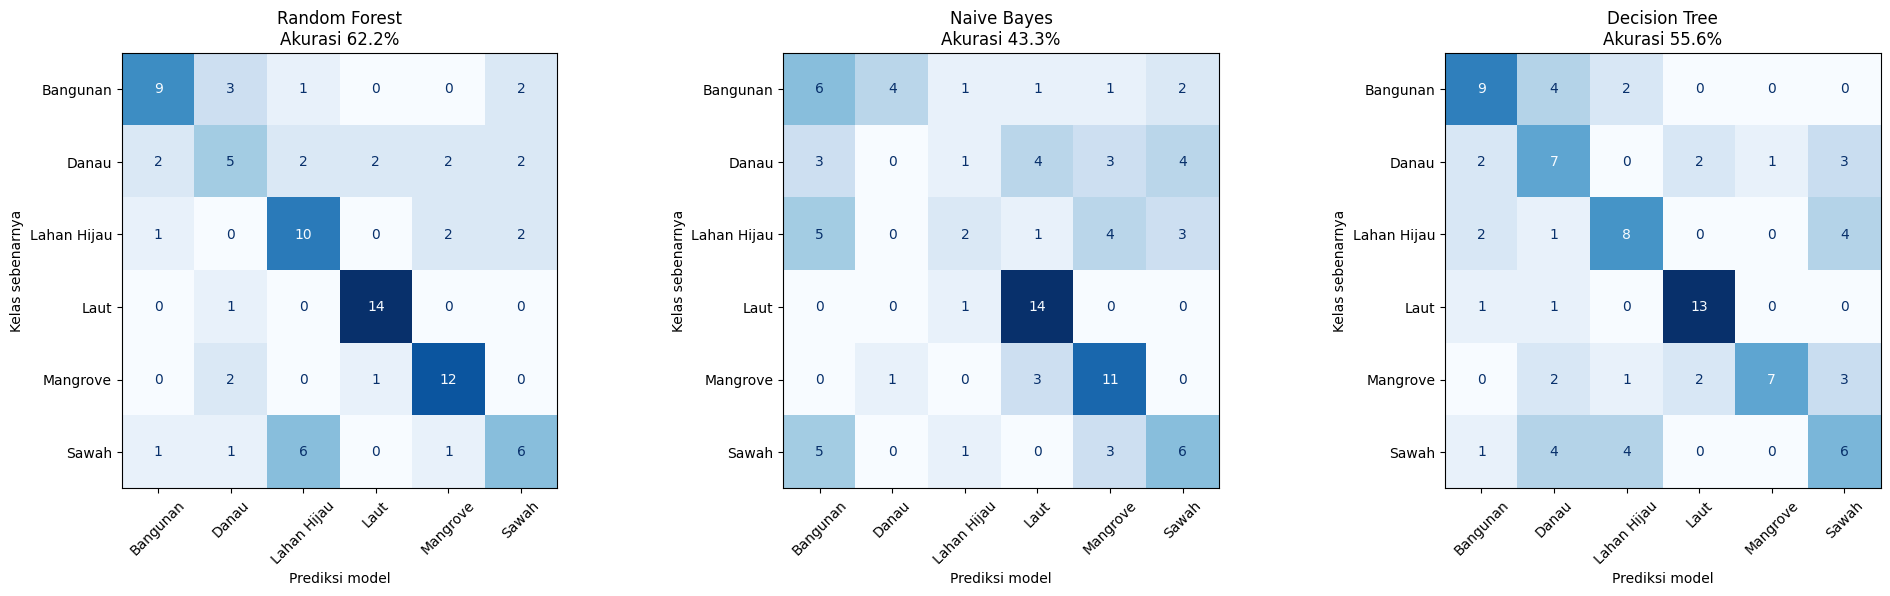

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay

kelas_list = list(model_terbaik.classes_)
prediksi_model = {"Random Forest": pred_rf, "Naive Bayes": pred_nb, "Decision Tree": pred_dt}

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (nama, pred) in zip(axes, prediksi_model.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=kelas_list, ax=ax,
        cmap="Blues", colorbar=False, xticks_rotation=45,
    )
    akurasi = (pred == y_test.values).mean()
    ax.set_title(f"{nama}\nAkurasi {akurasi:.1%}")
    ax.set_xlabel("Prediksi model")
    ax.set_ylabel("Kelas sebenarnya")
plt.tight_layout()
plt.show()

## 9. Membuat peta klasifikasi

Tahap ini tetap menggunakan Batch Job openEO, resolusi 100 meter, model Random Forest yang sudah dilatih, dan tampilan peta Matplotlib serta Folium.

**Catatan:** kode sumber menentukan `bbox_vis` dari batas sampel (`minx`, `miny`, `maxx`, `maxy`). Jadi cakupan peta mengikuti batas sampel, bukan otomatis seluruh Provinsi Jawa Timur. Ini dipertahankan agar perubahan tetap pada penyederhanaan kode, bukan perubahan metode/cakupan.

In [11]:
# Cakupan mengikuti bounding box sampel, seperti pada kode awal.
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from rasterio.warp import transform_bounds

kelas_list = list(model_terbaik.classes_)

with rasterio.open(nama_tif) as src:
    img = src.read()
    ext = [
        src.bounds.left, src.bounds.right,
        src.bounds.bottom, src.bounds.top
    ]
    lon_min, lat_min, lon_max, lat_max = transform_bounds(
        src.crs, "EPSG:4326", *src.bounds
    )

# Ambil lima band yang digunakan saat pelatihan.
b02, b03, b04, b08, b11 = [
    img[i].astype(np.float32) for i in range(5)
]

# Hitung indeks vegetasi dan air.
ndvi = (b08 - b04) / (b08 + b04 + 1e-6)
ndwi = (b03 - b08) / (b03 + b08 + 1e-6)

fitur_piksel = np.stack(
    [b02, b03, b04, b08, b11, ndvi, ndwi],
    axis=-1
)

h, w, jumlah_fitur = fitur_piksel.shape
flat = fitur_piksel.reshape(-1, jumlah_fitur)

# Identifikasi piksel valid.
valid = (
    np.isfinite(flat).all(axis=1)
    & np.all(flat[:, :5] != -32768, axis=1)
    & np.all(flat[:, :5] > 0, axis=1)
)

peta = np.full(h * w, np.nan, dtype=np.float32)
indeks_valid = np.flatnonzero(valid)

print(f"Ukuran raster       : {h} x {w}")
print(f"Total piksel        : {h * w:,}")
print(f"Piksel valid        : {len(indeks_valid):,}")
print(f"Model terbaik       : {nama_model_terbaik}")

# Gunakan nama fitur jika model dilatih dengan DataFrame.
fitur_nama = [
    "B02", "B03", "B04", "B08", "B11", "NDVI", "NDWI"
]

# Sesuaikan nama di atas jika nama kolom X_train berbeda.
gunakan_nama_fitur = hasattr(model_terbaik, "feature_names_in_")

if gunakan_nama_fitur:
    import pandas as pd
    fitur_nama = list(model_terbaik.feature_names_in_)
    if len(fitur_nama) != jumlah_fitur:
        raise ValueError(
            f"Model mengharapkan {len(fitur_nama)} fitur, "
            f"sedangkan raster menghasilkan {jumlah_fitur} fitur."
        )

# Prediksi bertahap agar tidak mengirim seluruh piksel sekaligus.
batch_size = 50000
mapping_kelas = {
    kelas: i for i, kelas in enumerate(kelas_list)
}

for awal in range(0, len(indeks_valid), batch_size):
    akhir = min(awal + batch_size, len(indeks_valid))
    idx = indeks_valid[awal:akhir]
    X_batch = flat[idx]

    if gunakan_nama_fitur:
        X_batch = pd.DataFrame(X_batch, columns=fitur_nama)

    prediksi = model_terbaik.predict(X_batch)
    peta[idx] = np.array(
        [mapping_kelas[k] for k in prediksi],
        dtype=np.float32
    )

peta = peta.reshape(h, w)

# Visualisasi hasil klasifikasi.
warna = ["red", "blue", "lime", "cyan", "purple", "yellow"]
n = len(kelas_list)

fig, ax = plt.subplots(figsize=(12, 7))
cmap = ListedColormap(warna[:n])
cmap.set_bad("white")

im = ax.imshow(
    np.ma.masked_invalid(peta),
    cmap=cmap,
    vmin=-0.5,
    vmax=n - 0.5,
    extent=ext
)

cbar = plt.colorbar(im, ax=ax, ticks=range(n), shrink=0.7)
cbar.ax.set_yticklabels(kelas_list)

ax.set_title("Peta Klasifikasi Tutupan Lahan")
ax.set_xlabel("Koordinat X")
ax.set_ylabel("Koordinat Y")
plt.tight_layout()
plt.show()


Ukuran raster       : 2352 x 3847
Total piksel        : 9,048,144
Piksel valid        : 8,981,084
Model terbaik       : Random Forest


KeyboardInterrupt: 

## 10. Peta interaktif Folium
Tampilkan citra satelit dan layer terpisah untuk setiap kelas.


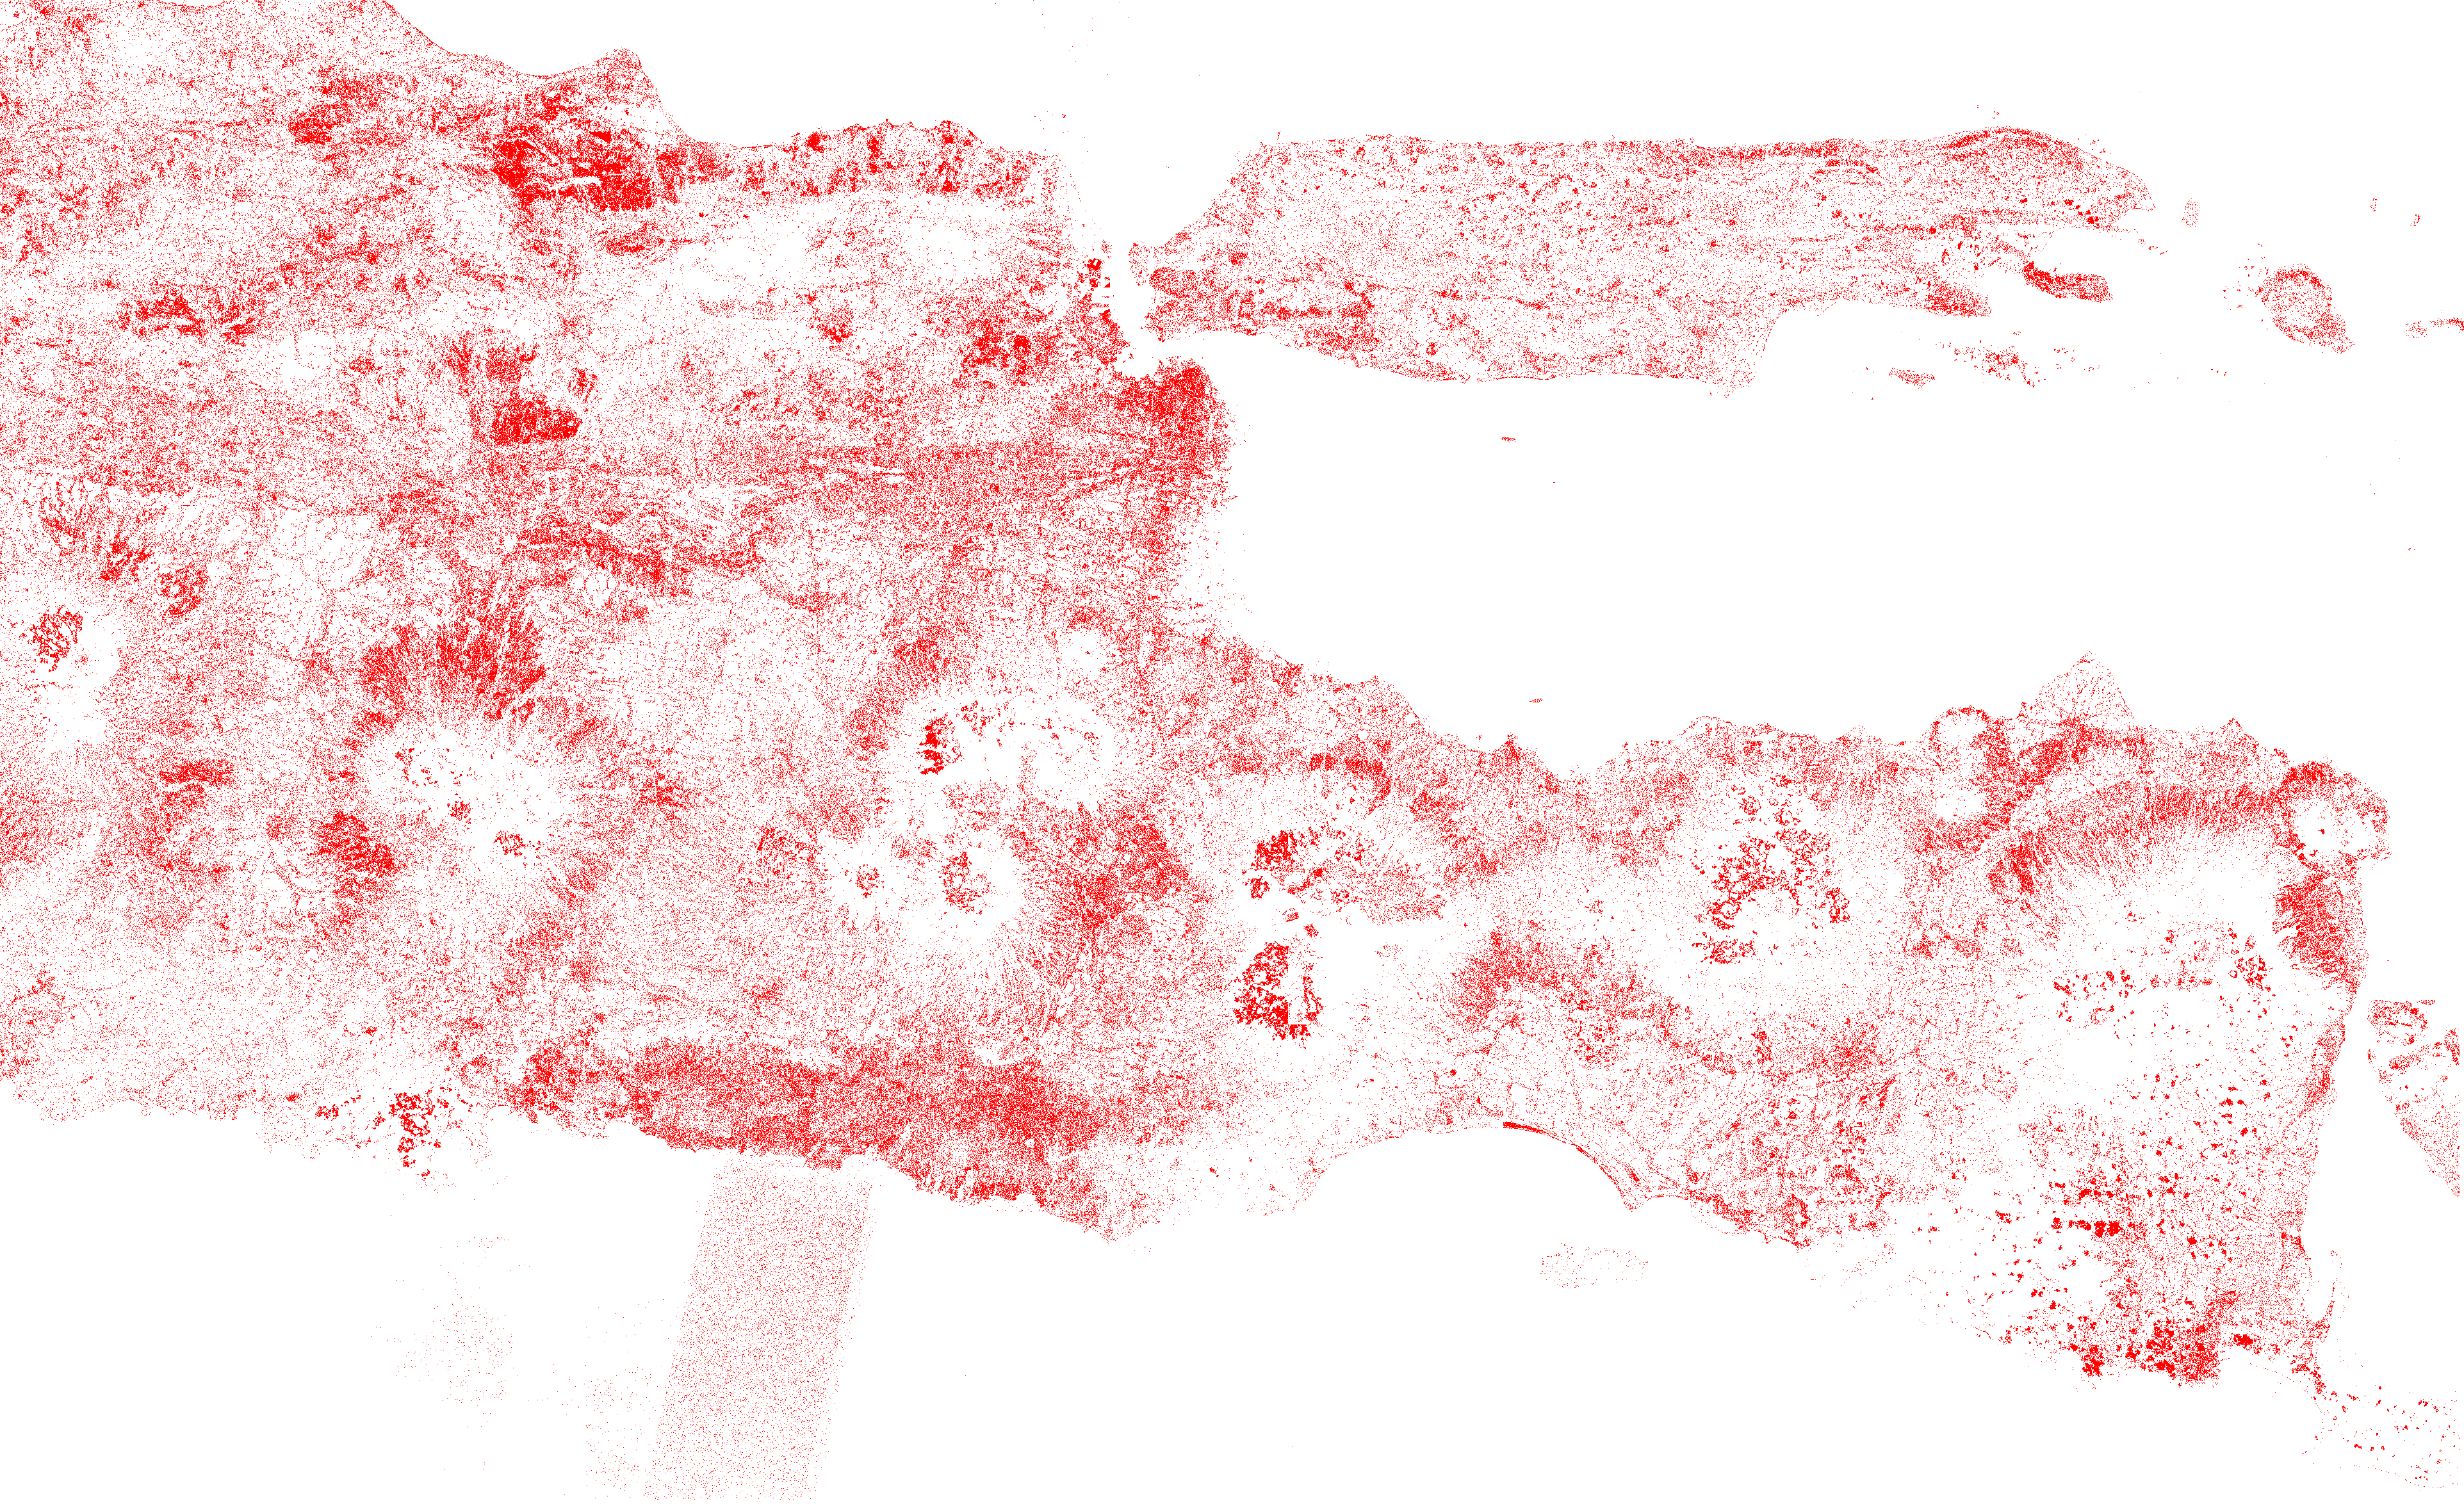
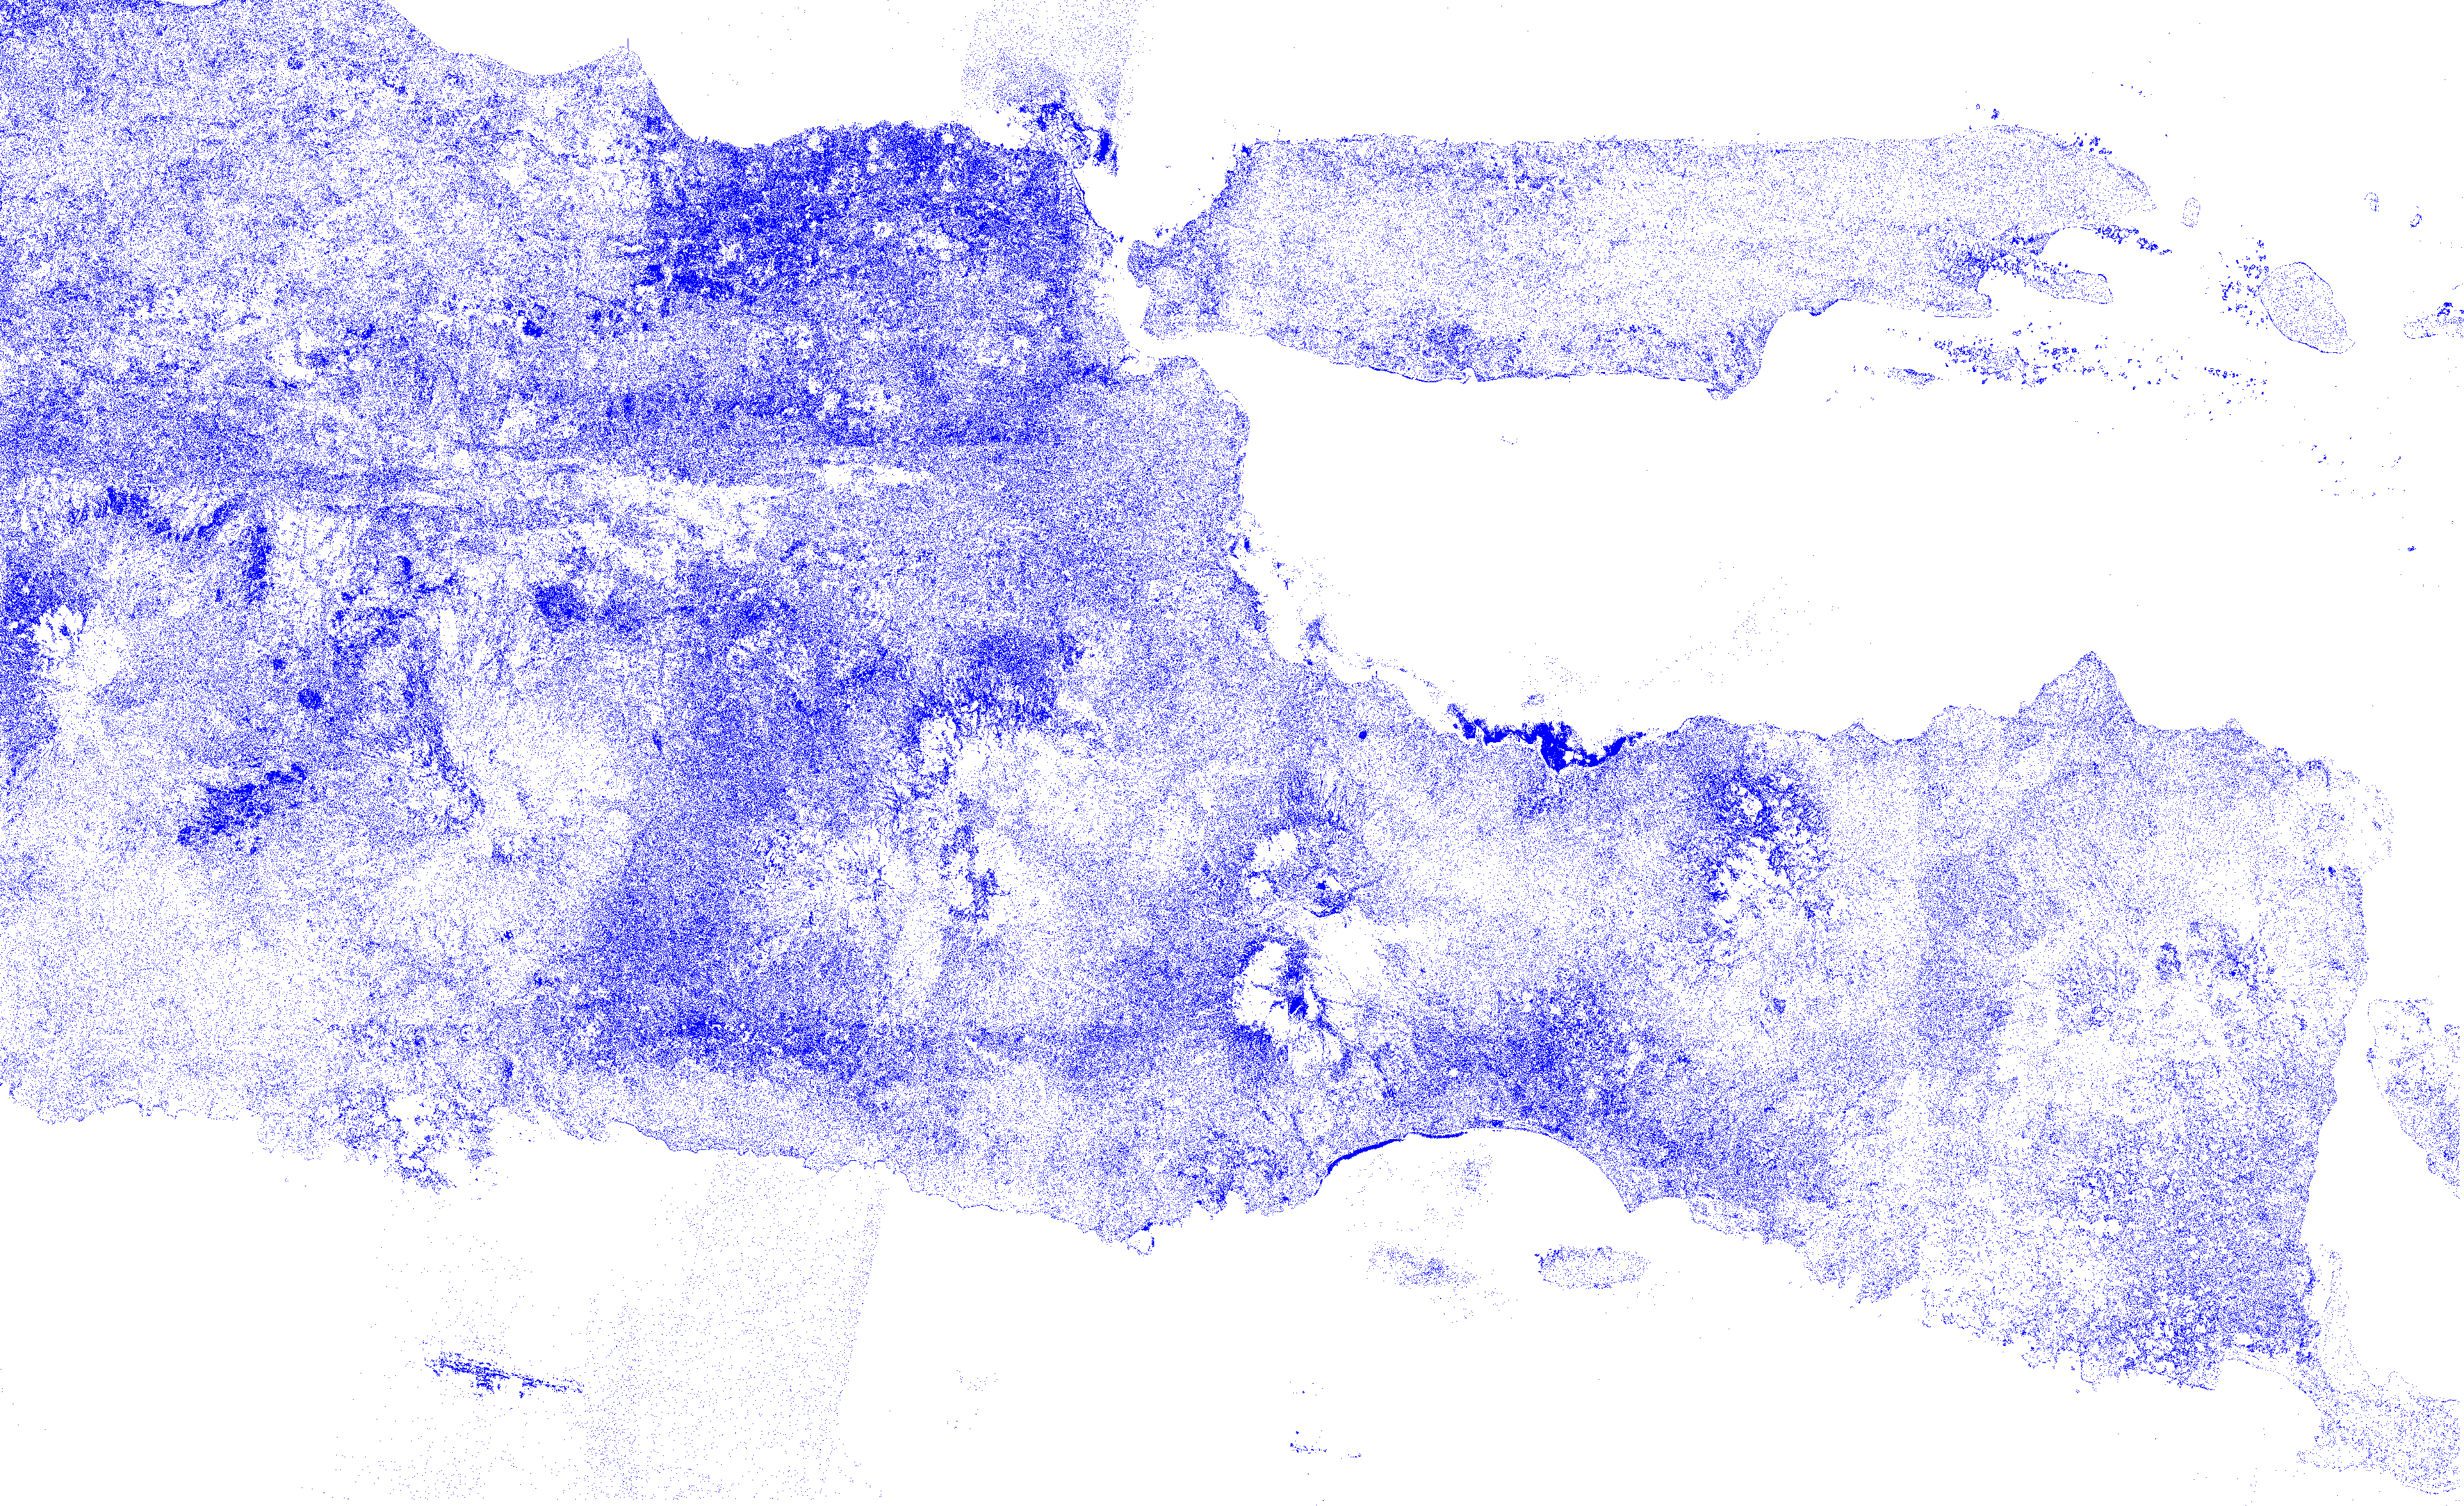
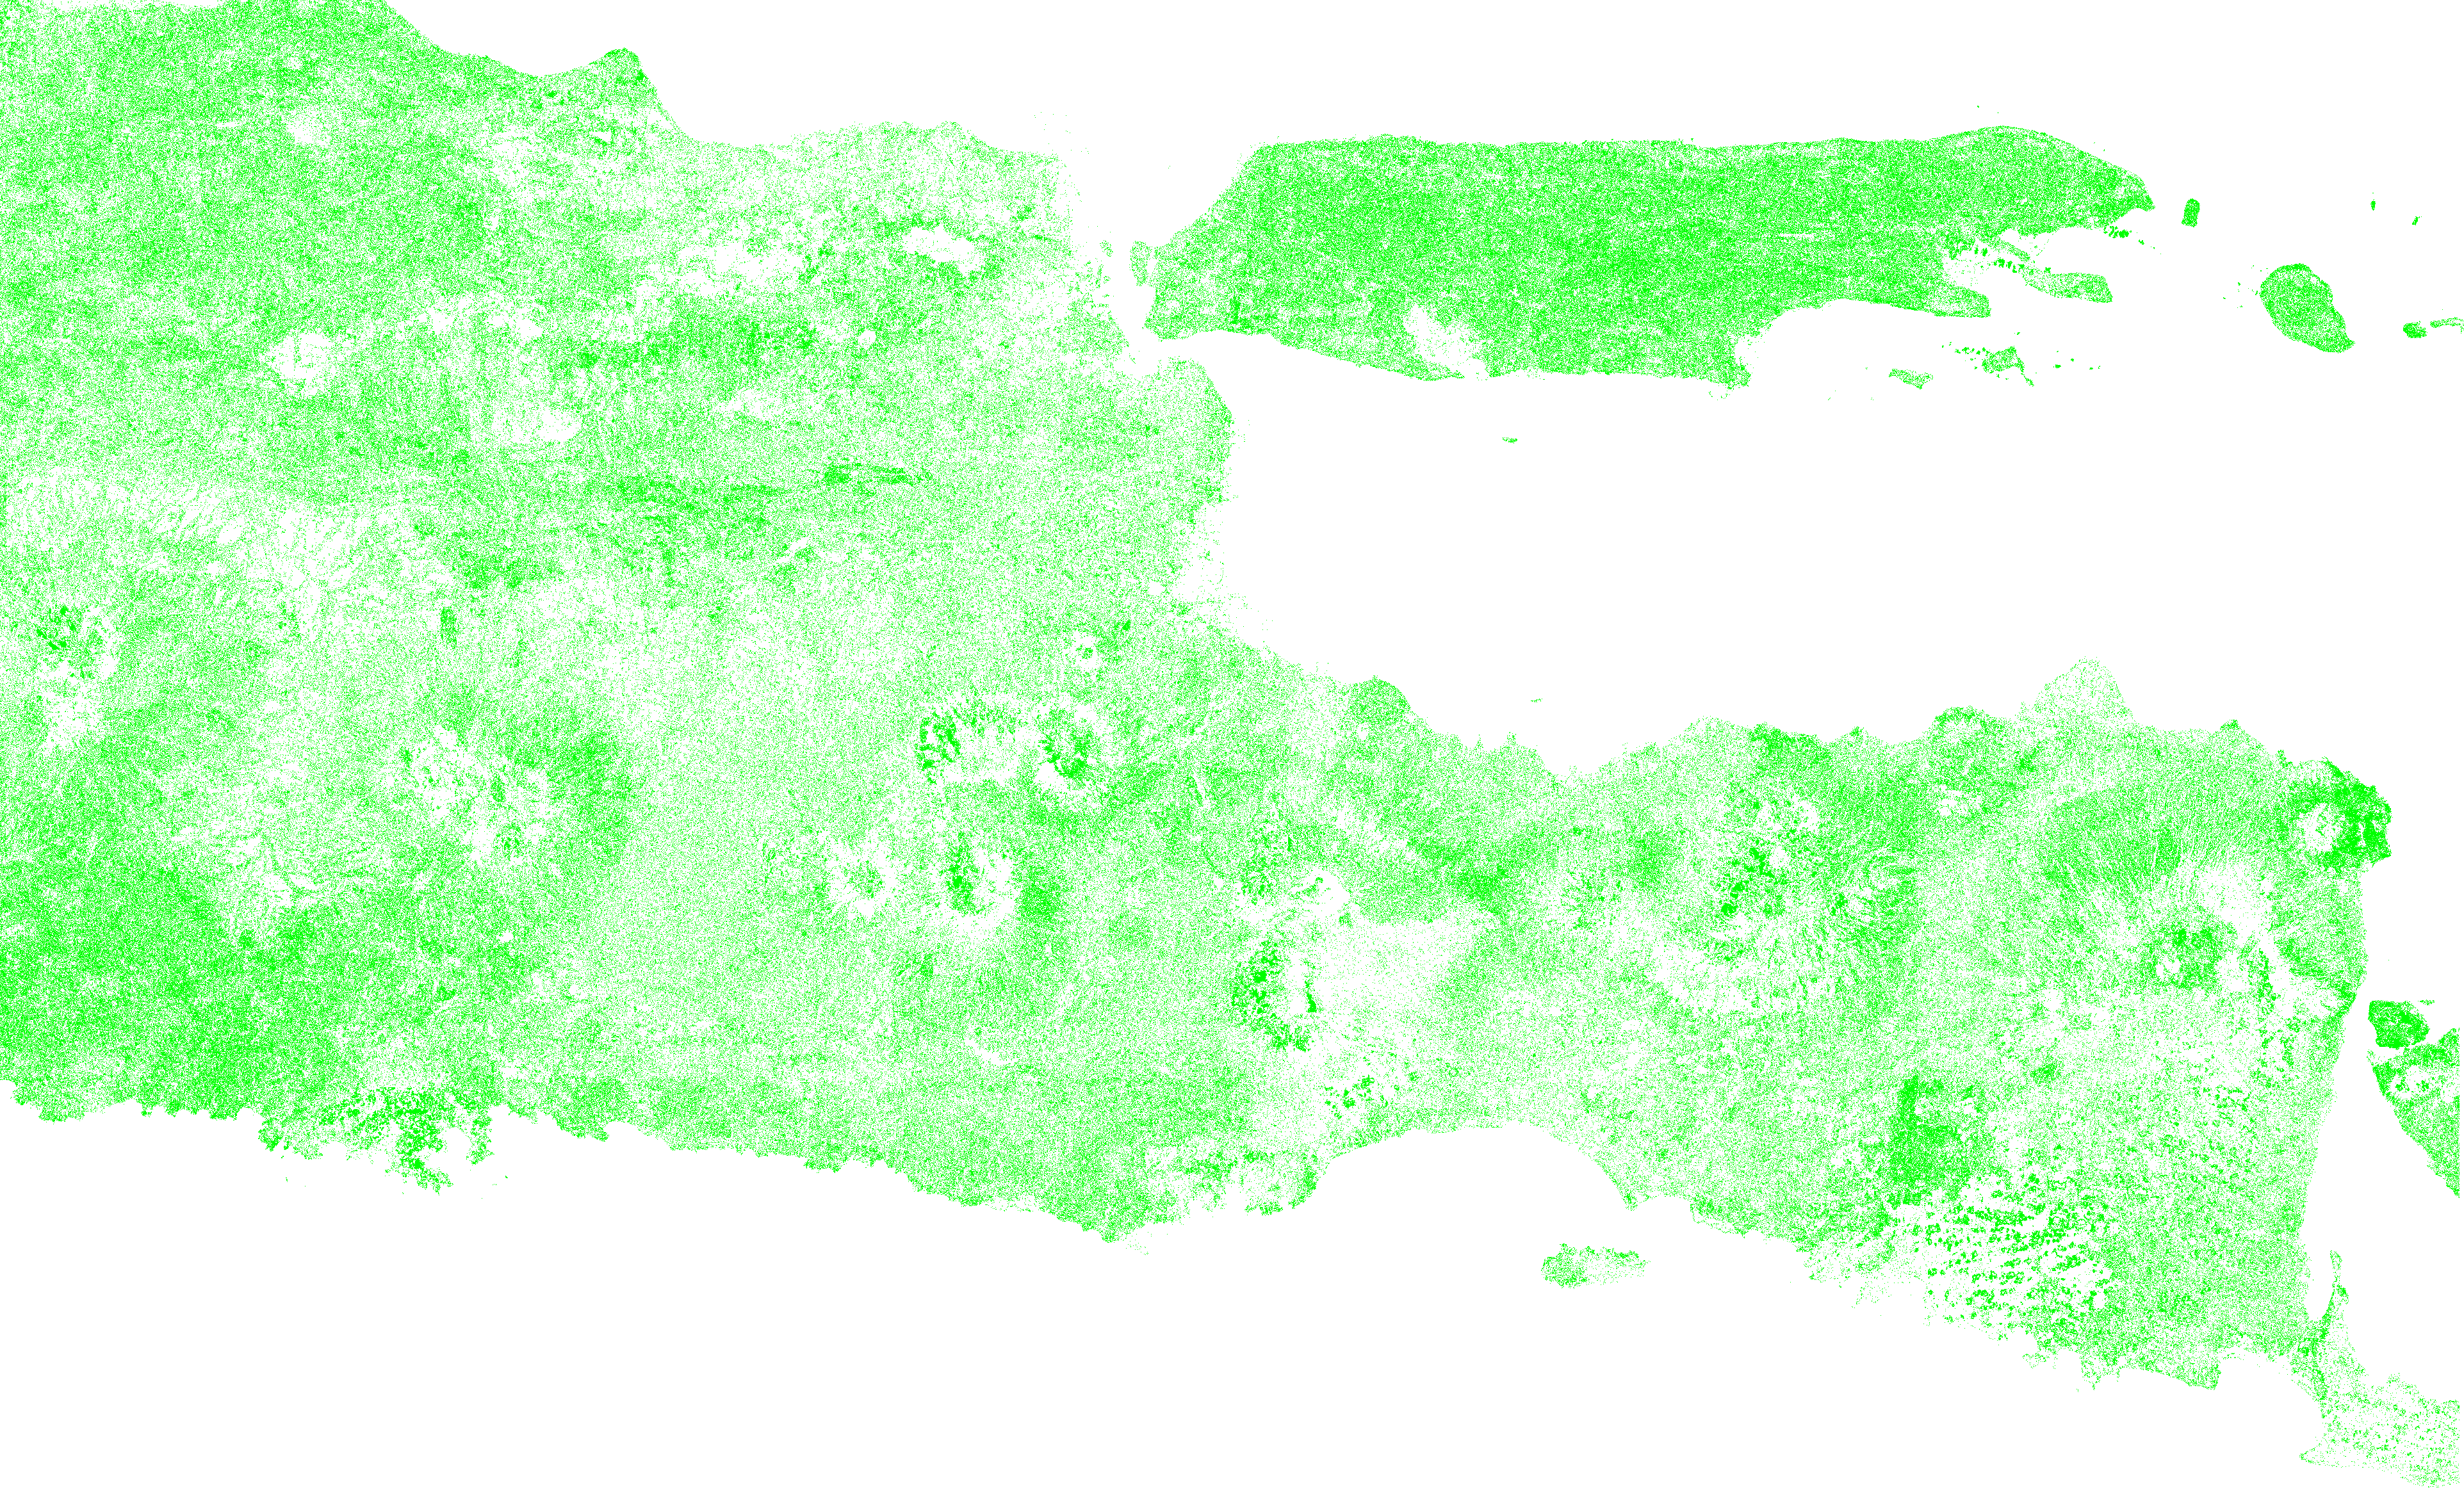
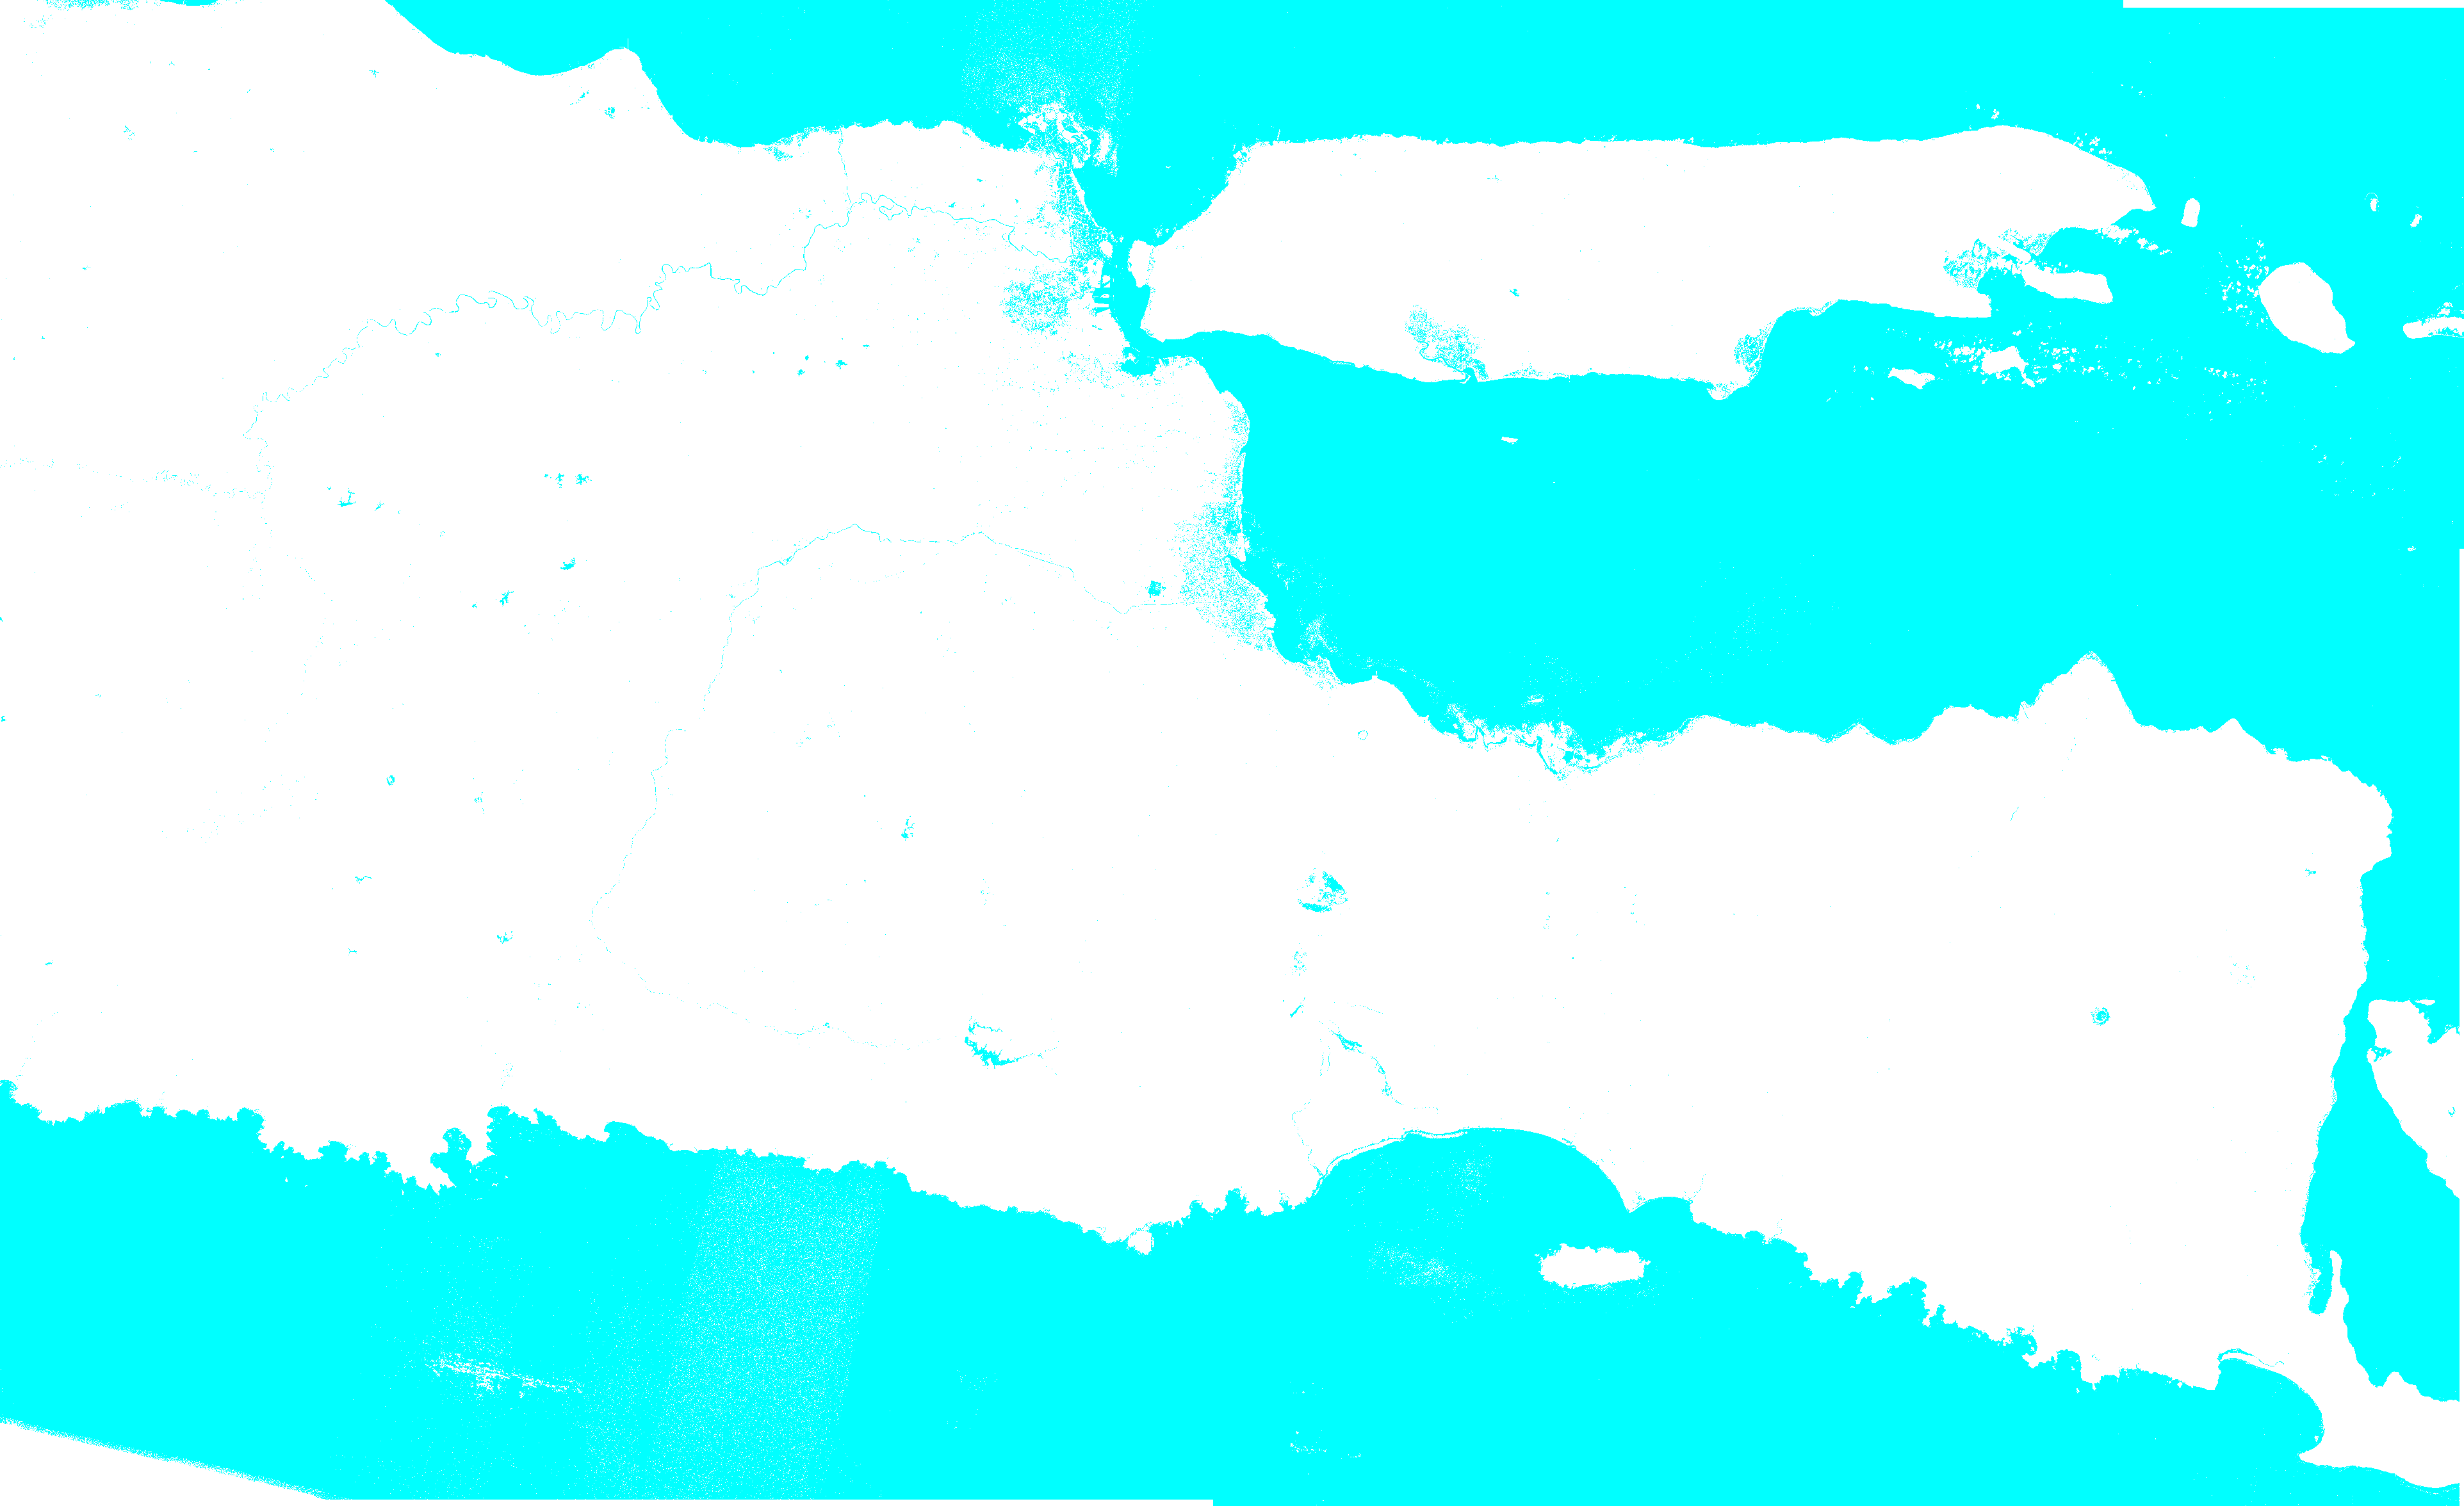
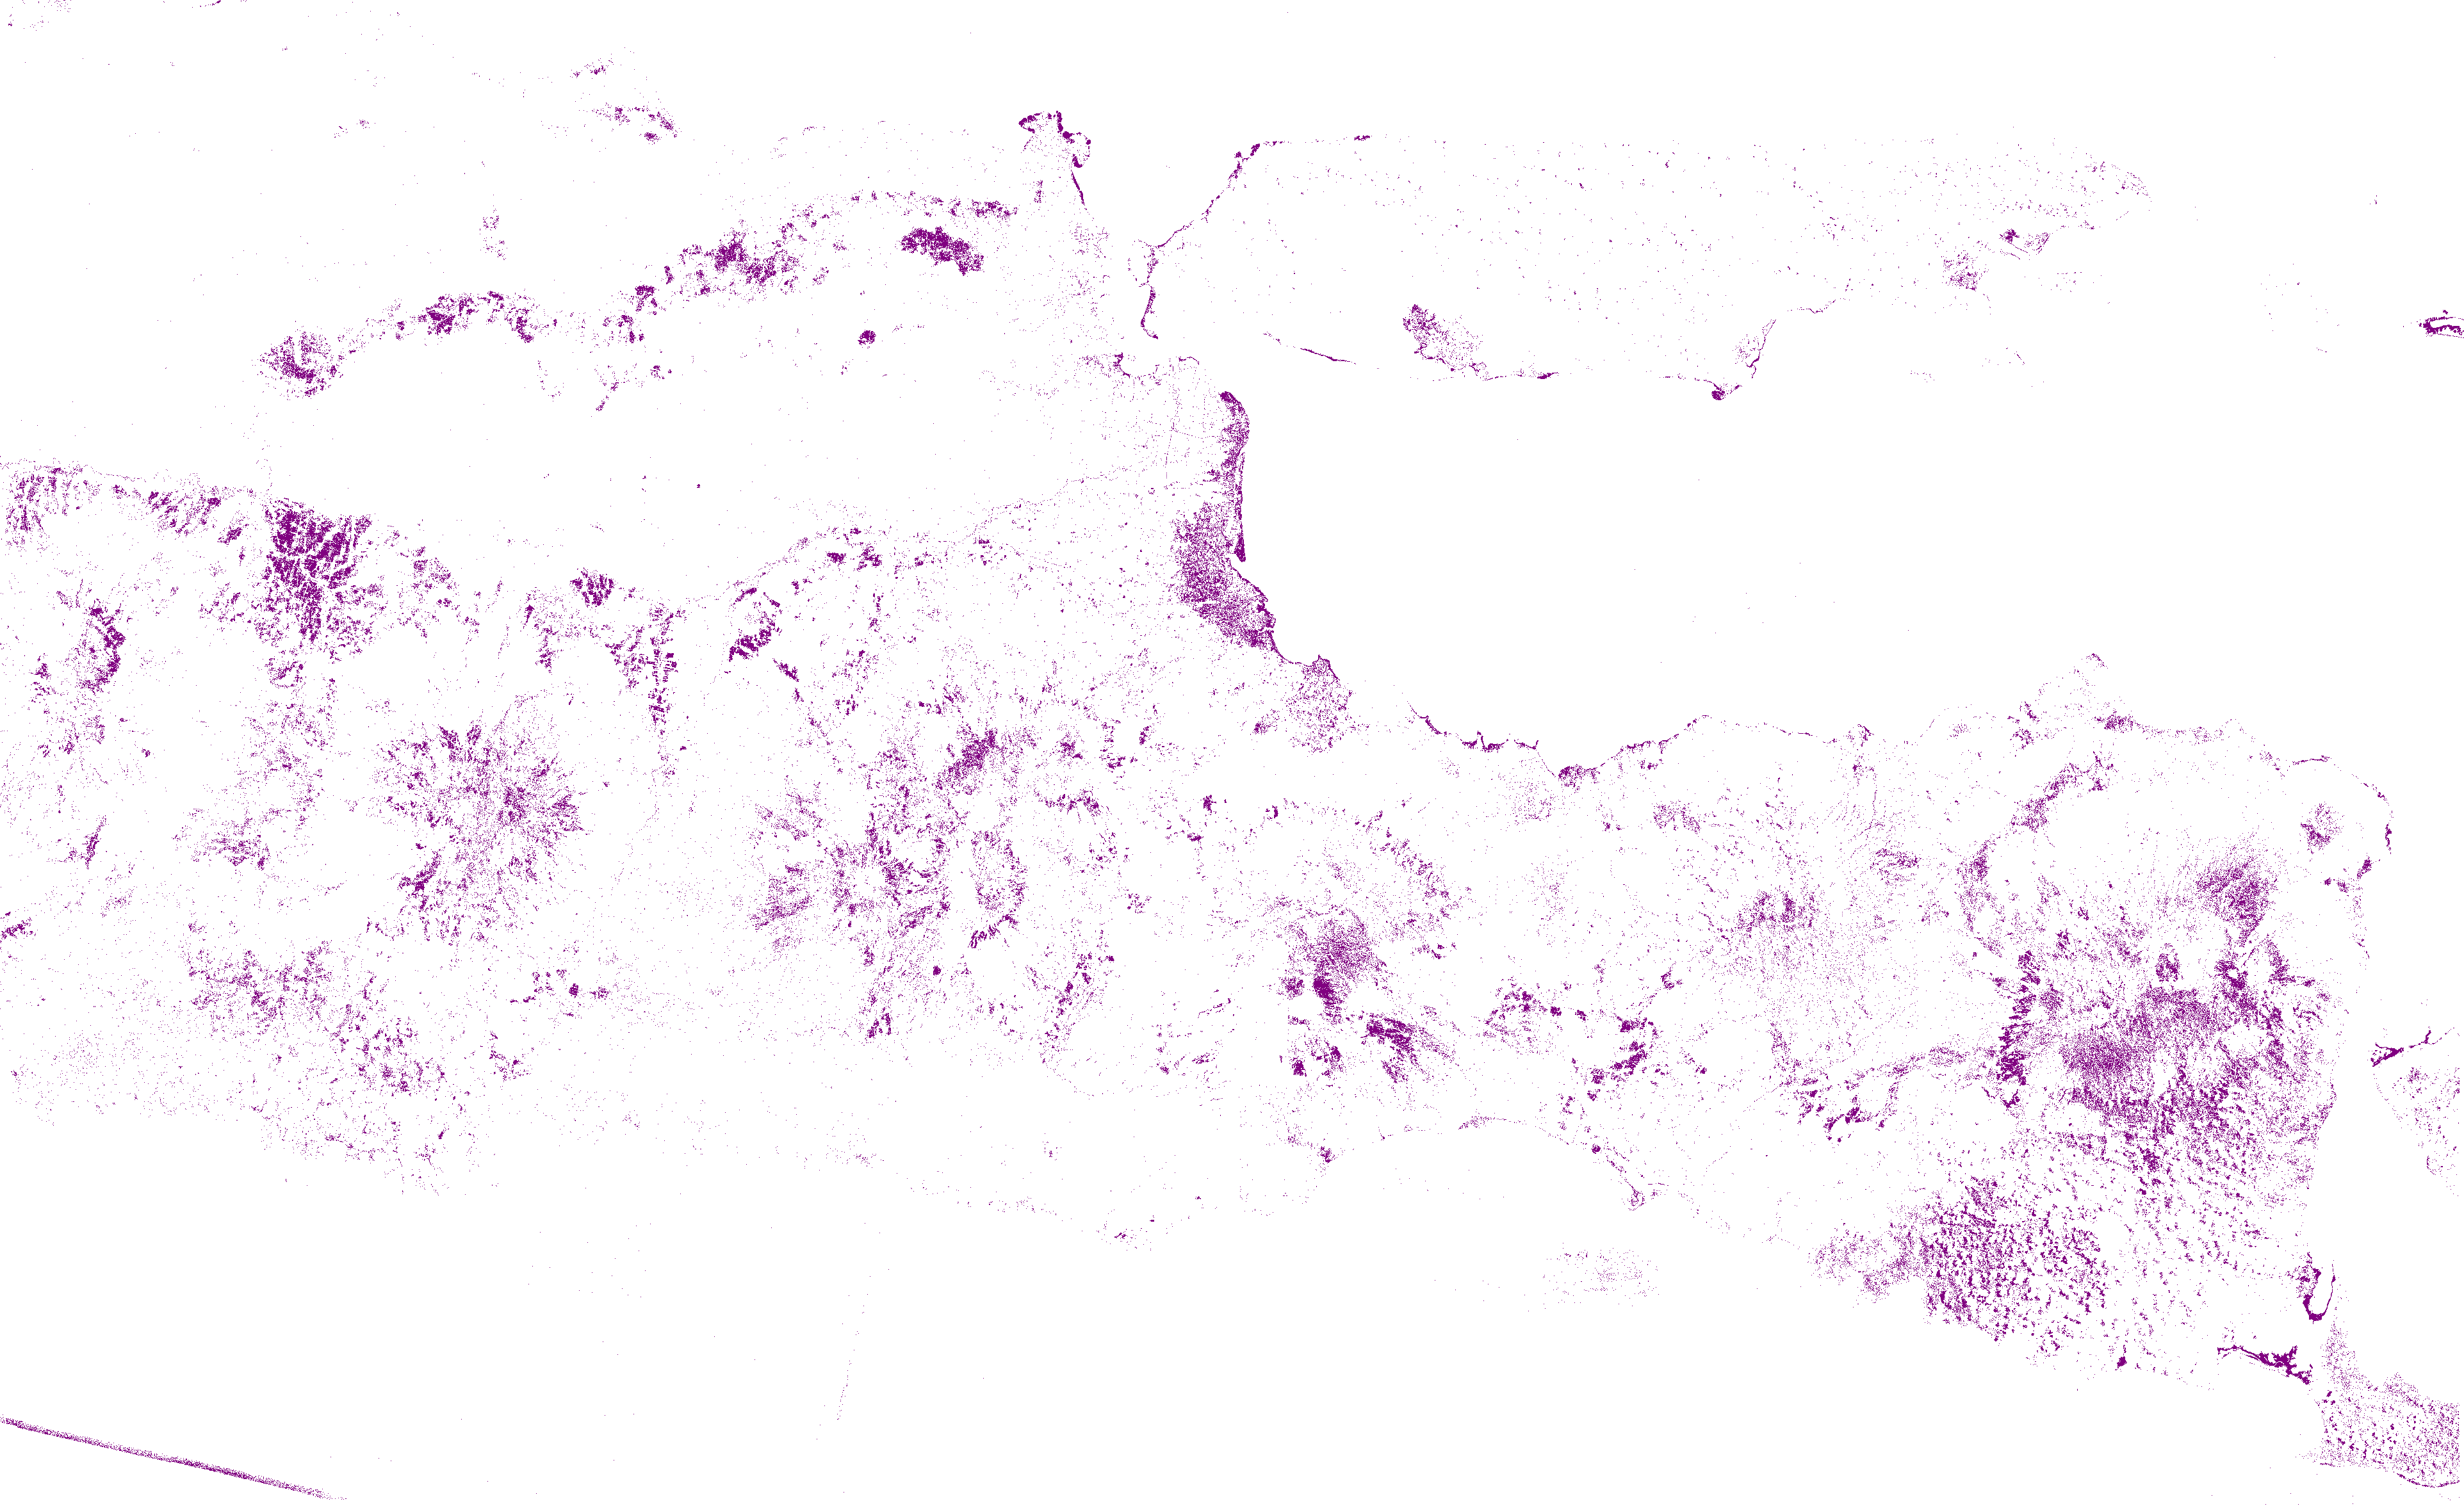
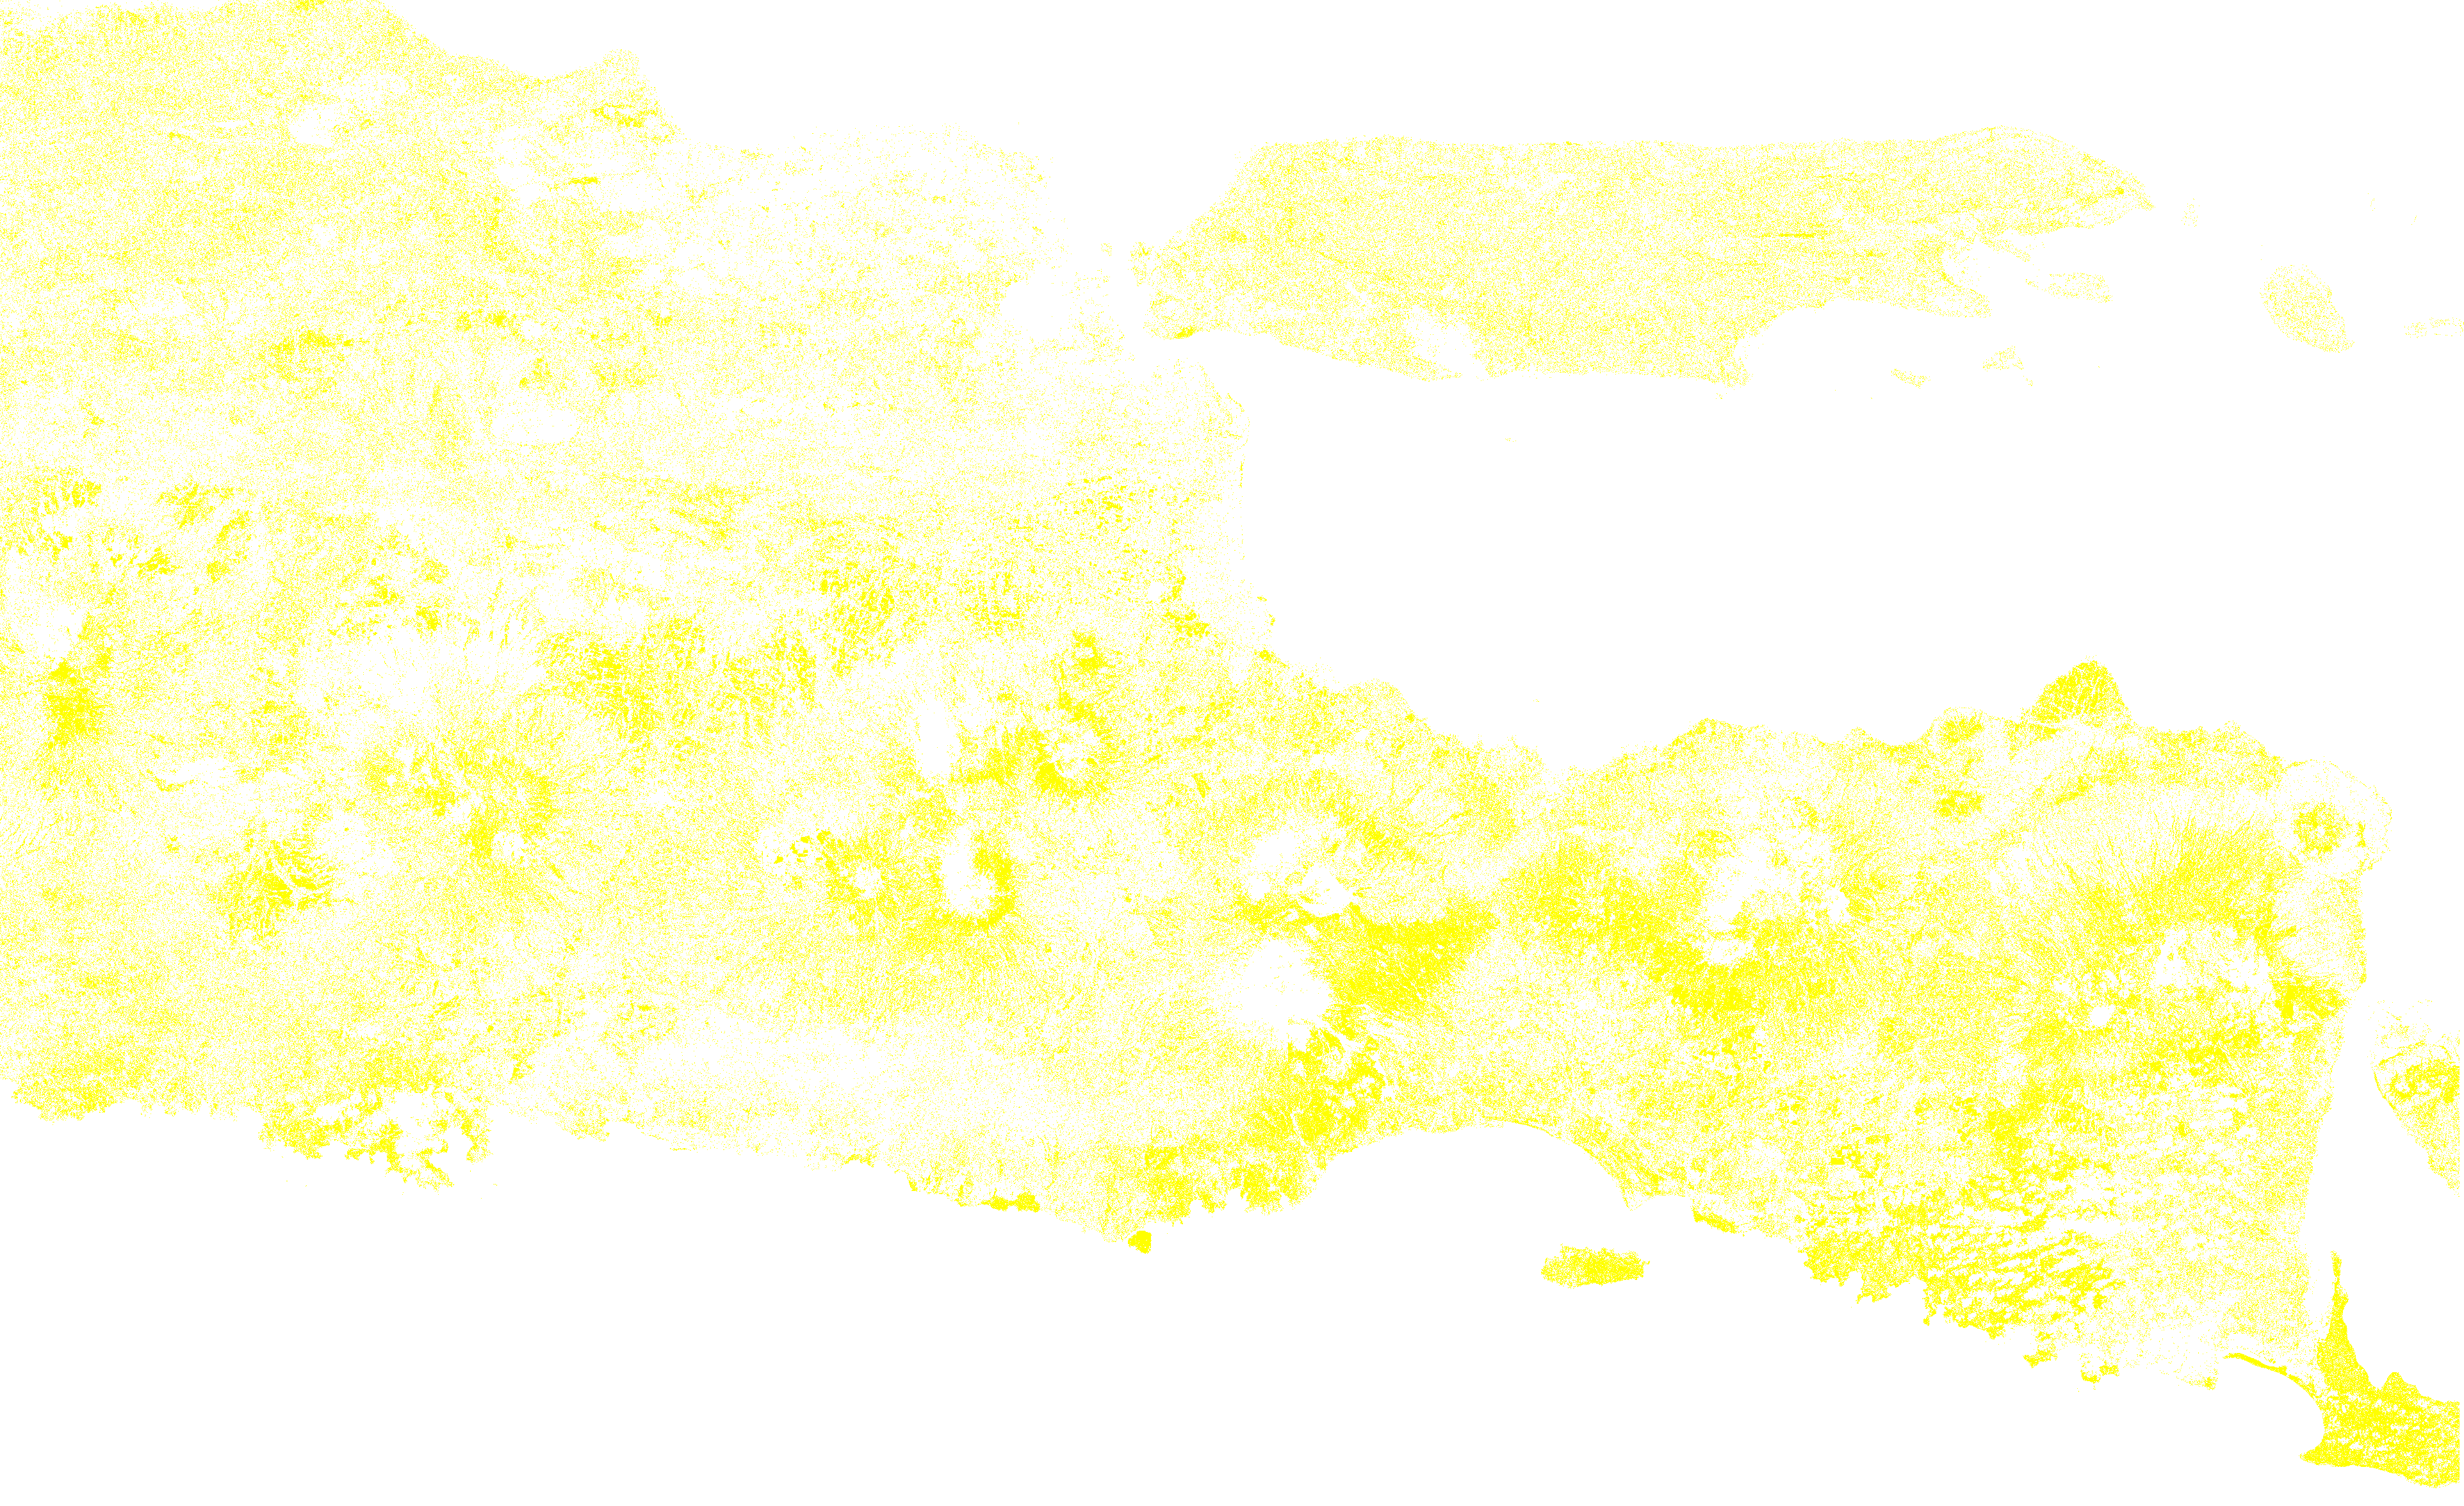

In [ ]:
batas_peta = [[lat_min, lon_min], [lat_max, lon_max]]
peta_folium = folium.Map(
    location=[(lat_min + lat_max) / 2, (lon_min + lon_max) / 2],
    zoom_start=8
)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Imagery",
    name="Peta Satelit Asli",
).add_to(peta_folium)

warna_rgba = [
    [255, 0, 0, 255], [0, 0, 255, 255], [0, 255, 0, 255],
    [0, 255, 255, 255], [128, 0, 128, 255], [255, 255, 0, 255]
]

for i, kelas in enumerate(kelas_list):
    layer = np.zeros((h, w, 4), dtype=np.uint8)
    layer[peta == i] = warna_rgba[i]
    folium.raster_layers.ImageOverlay(
        image=layer, bounds=batas_peta, opacity=0.6,
        name=f"Klasifikasi {kelas}"
    ).add_to(peta_folium)

folium.LayerControl(position="topright").add_to(peta_folium)
peta_folium

## Streamlit

Link : https://azes24.streamlit.app/